<a href="https://colab.research.google.com/github/sabbirpuspo/LearningforMe/blob/main/Clustering_Techniques_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup Enivironment


In [1]:
import os
import sys
import torch
import json
import re
import PIL
import math
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import warnings
import seaborn as sns
import shap


# Google Drive Connection

In [2]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully.")

df = pd.read_csv('/content/drive/MyDrive/SkillMorph Datasets/sgdata.csv')

Mounted at /content/drive
Google Drive connected successfully.


# Data Preprocessing and Exploration

In [3]:
df.head()

,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,single,67,university,124670,skilled employee / official,2
1,100000002,1,non-single (divorced / separated / married / w...,22,high school,150773,skilled employee / official,2
2,100000003,0,single,49,high school,89210,unemployed / unskilled,0
3,100000004,0,single,45,high school,171565,skilled employee / official,1
4,100000005,0,single,53,high school,149031,skilled employee / official,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   ID               2000 non-null   int64 
 1   Sex              2000 non-null   int64 
 2   Marital status   2000 non-null   object
 3   Age              2000 non-null   int64 
 4   Education        2000 non-null   object
 5   Income           2000 non-null   int64 
 6   Occupation       2000 non-null   object
 7   Settlement size  2000 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 125.1+ KB


In [6]:
# Selecting relevant columns for clustering (Income and Settlement size)
df = df[['Income', 'Settlement size']]

# Check for null values
df.isnull().sum()

,0
Income,0
Settlement size,0


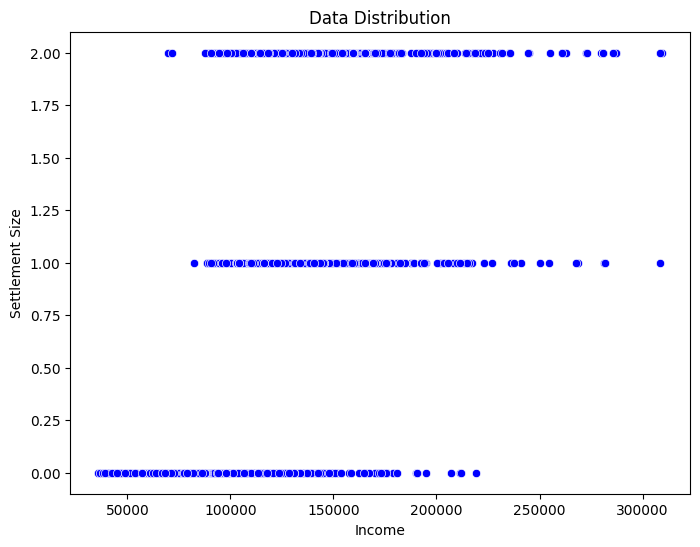

In [8]:
from sklearn.preprocessing import StandardScaler

# Standardize the data (important for K-Means)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

# Visualize the data distribution
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['Income'], y=df['Settlement size'], color='blue')
plt.title('Data Distribution')
plt.xlabel('Income')
plt.ylabel('Settlement Size')
plt.show()

# K-means clustering

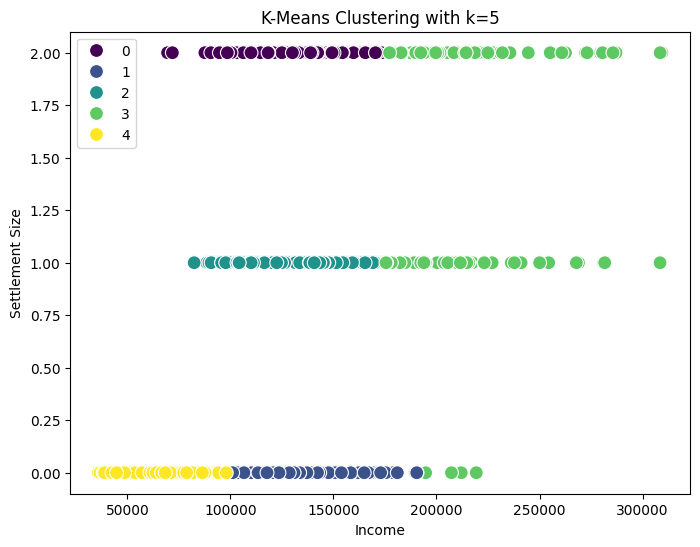

In [10]:
# --- K-Means Clustering ---
from sklearn.cluster import KMeans
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=20)
kmeans.fit(df_scaled)

# Visualize the K-Means clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['Income'], y=df['Settlement size'], hue=kmeans.labels_, palette='viridis', s=100)
plt.title(f'K-Means Clustering with k={optimal_k}')
plt.xlabel('Income')
plt.ylabel('Settlement Size')
plt.show()

# Hierarchical Clustering

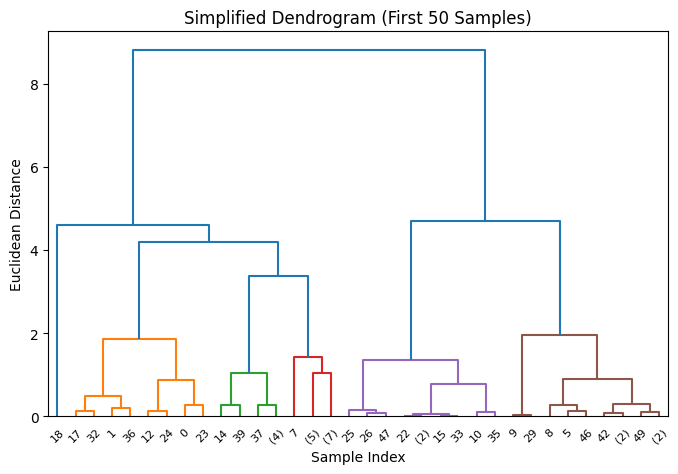

In [11]:
# --- Hierarchical Clustering (Simplified Dendrogram) ---
# Use a subset of the data to keep visualization readable
from scipy.cluster.hierarchy import dendrogram, linkage
sample_data = df_scaled[:50]  # taking first 50 samples

# Create linkage matrix
linked = linkage(sample_data, method='ward')

# Plot the simplified dendrogram
plt.figure(figsize=(8, 5))
dendrogram(
    linked,
    truncate_mode='level',  # show only top levels of the tree
    p=5,                    # show last 5 merges
    color_threshold=3
)
plt.title('Simplified Dendrogram (First 50 Samples)')
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
plt.show()

# Comparison between K-means and Hierarchical

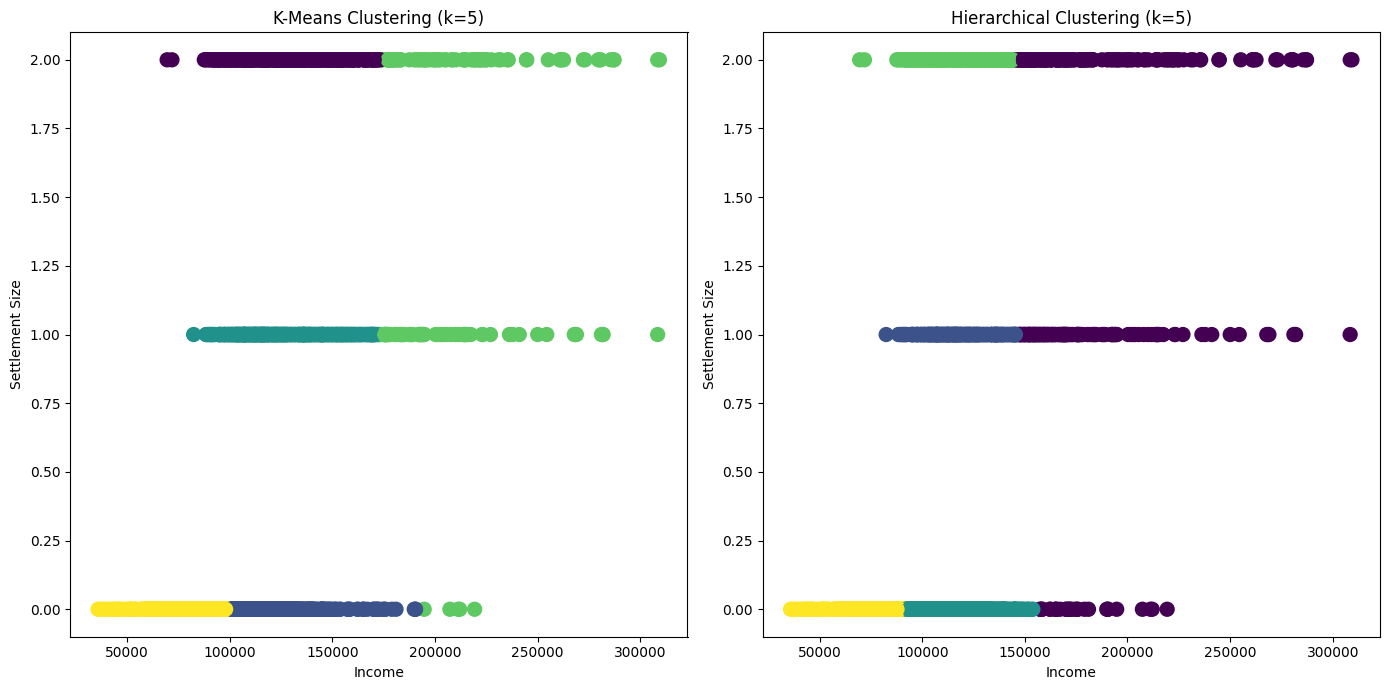

In [13]:
# Apply Agglomerative Clustering (Hierarchical) with k=5
from sklearn.cluster import AgglomerativeClustering
hierarchical = AgglomerativeClustering(n_clusters=5, linkage='ward')
y_hc = hierarchical.fit_predict(df_scaled)

# Plot the comparison of K-Means and Hierarchical Clustering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# K-Means plot
ax1.scatter(df['Income'], df['Settlement size'], c=kmeans.labels_, cmap='viridis', s=100)
ax1.set_title(f'K-Means Clustering (k={optimal_k})')
ax1.set_xlabel('Income')
ax1.set_ylabel('Settlement Size')

# Hierarchical plot
ax2.scatter(df['Income'], df['Settlement size'], c=y_hc, cmap='viridis', s=100)
ax2.set_title('Hierarchical Clustering (k=5)')
ax2.set_xlabel('Income')
ax2.set_ylabel('Settlement Size')

plt.tight_layout()
plt.show()